# PBL 3: Hidden Markov Model on Blood-Glucose Sequences

**Project:** Explainable Machine Learning for Early Prediction of Diabetes Risk Using Clinical Data
**Team 3:** Jai (RA2411026010131), Aggam (RA2411026010139), Alphin (RA2411026010177)
**Assigned topic:** Hidden Markov Model (HMM)

PBL 1 and PBL 2 used one snapshot per patient. Real diabetes care produces **sequences**: a patient measures glucose several times a day for weeks. Here we use a **new sequential dataset** and an HMM to find the hidden glucose "regimes" (low / in target / high) that a patient moves through over time, how long each regime lasts, and how likely the patient is to move from one to another.

| # | Rubric item | Marks | Section |
|---|---|---|---|
| 1 | Understanding the new dataset, temporal structure and sequential preprocessing | 2 | B |
| 2 | Correct implementation of the HMM (forward-backward, Viterbi, Baum-Welch) | 4 | A, C |
| 3 | Sequential model evaluation, visualisation and interpretation | 2 | D |
| 4 | Demonstration, conceptual understanding and viva | 2 | whole notebook |

## Setup
Import libraries, set one random seed, and create the figure folder. We use `hmmlearn` for the HMM; it follows the scikit-learn style (`fit`, `score`, `predict`).

In [1]:
import os
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from scipy.special import logsumexp
from sklearn.model_selection import train_test_split
from sklearn.mixture import GaussianMixture
from hmmlearn.hmm import GaussianHMM

RANDOM_STATE = 42  # used everywhere so results are reproducible
logging.getLogger("hmmlearn").setLevel(logging.ERROR)   # hide hmmlearn's progress messages
os.makedirs("figures/pbl3", exist_ok=True)

# Section A: The Idea

## A.1 Markov chain
A sequence of states $z_1, z_2, \dots, z_T$ is a **Markov chain** if the next state depends only on the current one:
$$P(z_t \mid z_1, \dots, z_{t-1}) = P(z_t \mid z_{t-1})$$
This is described by a **transition matrix** $A$, with $a_{ij} = P(z_t = j \mid z_{t-1} = i)$ (each row sums to 1).

## A.2 Hidden Markov Model
In an HMM we **do not see** the states. We only see observations $x_t$ (here: glucose readings in mg/dL) that depend on the hidden state. An HMM with $K$ states has three parts, $\lambda = (\pi, A, B)$:
- $\pi_i = P(z_1 = i)$: the **start** probabilities
- $A$: the **transition** matrix (how the hidden regime changes between readings)
- $B$: the **emission** distributions. We use one Gaussian per state: $b_j(x_t) = \mathcal{N}(x_t \mid \mu_j, \sigma_j^2)$

For us a hidden state is a **glucose regime**, for example "low", "in target" or "high". A single reading is noisy, but the regime behind it is persistent, which is exactly what an HMM models.

## A.3 The three HMM problems and their algorithms

| Problem | Question | Algorithm |
|---|---|---|
| 1. Evaluation | How likely is this sequence under the model, $P(x_{1:T} \mid \lambda)$? | **Forward** algorithm |
| 2. Decoding | What is the most likely hidden state sequence? | **Viterbi** algorithm |
| 3. Learning | Which $\pi, A, B$ best explain the data? | **Baum-Welch** (= EM, uses **forward-backward**) |

**Forward:** $\alpha_t(j) = P(x_1, \dots, x_t, z_t = j)$, computed step by step:
$$\alpha_1(j) = \pi_j\, b_j(x_1) \qquad \alpha_t(j) = \Big[\sum_{i=1}^{K} \alpha_{t-1}(i)\, a_{ij}\Big] b_j(x_t) \qquad P(x_{1:T}) = \sum_j \alpha_T(j)$$

**Backward:** $\beta_t(i) = P(x_{t+1}, \dots, x_T \mid z_t = i)$:
$$\beta_T(i) = 1 \qquad \beta_t(i) = \sum_{j=1}^{K} a_{ij}\, b_j(x_{t+1})\, \beta_{t+1}(j)$$

**Forward-backward** combines them into the probability of each state at each time:
$$\gamma_t(i) = P(z_t = i \mid x_{1:T}) = \frac{\alpha_t(i)\,\beta_t(i)}{\sum_j \alpha_t(j)\,\beta_t(j)}$$

**Viterbi:** same recursion as forward, but with **max** instead of sum, plus back-pointers to recover the best path:
$$\delta_t(j) = \max_i \big[\delta_{t-1}(i)\, a_{ij}\big]\, b_j(x_t)$$

**Baum-Welch** is the EM algorithm from PBL 2 applied to an HMM:
- **E-step:** use forward-backward to get $\gamma_t(i)$ and $\xi_t(i,j) = P(z_t = i, z_{t+1} = j \mid x_{1:T})$
- **M-step:** re-estimate
$$\pi_i = \gamma_1(i) \qquad a_{ij} = \frac{\sum_t \xi_t(i,j)}{\sum_t \gamma_t(i)} \qquad \mu_j = \frac{\sum_t \gamma_t(j)\,x_t}{\sum_t \gamma_t(j)} \qquad \sigma_j^2 = \frac{\sum_t \gamma_t(j)\,(x_t-\mu_j)^2}{\sum_t \gamma_t(j)}$$

As in PBL 2, every round never decreases the likelihood and the result is a local maximum. The only difference from a GMM is that the hidden group of reading $t$ now **depends on the group of reading $t-1$** through $A$.

All products of many small probabilities underflow to 0 on long sequences, so in practice everything is computed with **logarithms** ($\log \sum e^{\cdot}$ instead of $\sum$).

# Section B: The New Sequential Dataset *(Rubric 1)*

## B.1 Load the data
**AIM-94 Diabetes dataset** (Michael Kahn, Washington University; UCI Machine Learning Repository). 70 patients with insulin-dependent diabetes, several weeks to months of records each. Every file `data-01 ... data-70` has one record per line:

| Field | Meaning |
|---|---|
| date | MM-DD-YYYY |
| time | HH:MM |
| code | what was recorded (glucose reading, insulin dose, meal, exercise, ...) |
| value | the number (mg/dL for glucose, units for insulin) |

Some records come from an electronic meter with real time stamps; others come from paper diaries where the time is fixed per meal slot (08:00, 12:00, 18:00, 22:00).

In [2]:
frames = []
for i in range(1, 71):
    df = pd.read_csv(f"data/uci_diabetes/data-{i:02d}", sep="\t", header=None,
                     names=["date", "time", "code", "value"], dtype=str)
    df["patient"] = i
    frames.append(df)
raw = pd.concat(frames, ignore_index=True)

print(raw.shape)
raw.head()

(29330, 5)


,date,time,code,value,patient
0,04-21-1991,9:09,58,100,1
1,04-21-1991,9:09,33,009,1
2,04-21-1991,9:09,34,013,1
3,04-21-1991,17:08,62,119,1
4,04-21-1991,17:08,33,007,1


## B.2 Keep only the glucose readings
The codes 48 and 57 to 64 are blood-glucose measurements (the others are insulin doses, meals, exercise, symptoms). We keep those, turn `value` into a number and `date + time` into a timestamp, and drop records that cannot be parsed (for example the date "06-31-1991", which does not exist). We also drop readings below 20 mg/dL, which a glucose meter cannot really produce (data-entry errors).

In [3]:
glucose_codes = {"48": "unspecified", "57": "unspecified", "58": "pre-breakfast",
                 "59": "post-breakfast", "60": "pre-lunch", "61": "post-lunch",
                 "62": "pre-supper", "63": "post-supper", "64": "pre-snack"}

g = raw[raw["code"].isin(glucose_codes)].copy()
g["slot"] = g["code"].map(glucose_codes)
g["glucose"] = pd.to_numeric(g["value"], errors="coerce")          # bad text -> NaN
g["datetime"] = pd.to_datetime(g["date"] + " " + g["time"],
                               format="%m-%d-%Y %H:%M", errors="coerce")  # bad date -> NaT
print("Glucose records:", len(g))
print("Unreadable value or date:", g[["glucose", "datetime"]].isnull().any(axis=1).sum())
print("Below 20 mg/dL:", (g["glucose"] < 20).sum())

g = g.dropna(subset=["glucose", "datetime"])
g = g[g["glucose"] >= 20]
g = g.sort_values(["patient", "datetime"]).reset_index(drop=True)   # time order inside each patient
print("Clean readings:", len(g), "from", g["patient"].nunique(), "patients")
g["glucose"].describe().round(1)

Glucose records: 13531
Unreadable value or date: 13
Below 20 mg/dL: 3
Clean readings: 13515 from 70 patients


count    13515.0
mean       160.3
std         80.1
min         20.0
25%         97.0
50%        149.0
75%        210.0
max        501.0
Name: glucose, dtype: float64

**Observation:** There are 13,531 glucose records. 13 have an unreadable value or date, and 3 are below 20 mg/dL; these are removed, leaving **13,515 readings from 70 patients**. The median is 149 mg/dL and a quarter of readings are above 210, so many readings are above the usual target range of 70-180 mg/dL. That is typical for insulin-dependent patients with the home meters and insulin of the early 1990s.

## B.3 Temporal structure
Before modelling a sequence we check what the sequence looks like:
1. how many readings each patient has (the sequence length $T$),
2. how much time passes between two readings,
3. when in the day readings are taken,
4. whether a reading tells us something about the next one (lag-1 autocorrelation):
$$r_1 = \text{corr}(x_t, x_{t-1})$$
computed inside each patient (we never pair the last reading of one patient with the first of the next).

In [4]:
per_patient = g.groupby("patient").size()
gap_hours = g.groupby("patient")["datetime"].diff().dt.total_seconds() / 3600
previous = g.groupby("patient")["glucose"].shift(1)     # reading t-1 of the same patient

print("Readings per patient: median", per_patient.median(), " min", per_patient.min(), " max", per_patient.max())
print("Hours between readings: median", round(gap_hours.median(), 1))
print("Lag-1 autocorrelation:", round(g["glucose"].corr(previous), 3))

shuffled = g["glucose"].sample(frac=1, random_state=RANDOM_STATE).values
print("Same after shuffling the order:", round(np.corrcoef(shuffled[1:], shuffled[:-1])[0, 1], 3))
g["slot"].value_counts()

Readings per patient: median 120.0  min 31  max 616
Hours between readings: median 6.0
Lag-1 autocorrelation: 0.186
Same after shuffling the order: 0.0


slot
pre-breakfast     3516
pre-supper        3156
unspecified       2869
pre-lunch         2766
pre-snack          903
post-supper        219
post-lunch          66
post-breakfast      20
Name: count, dtype: int64

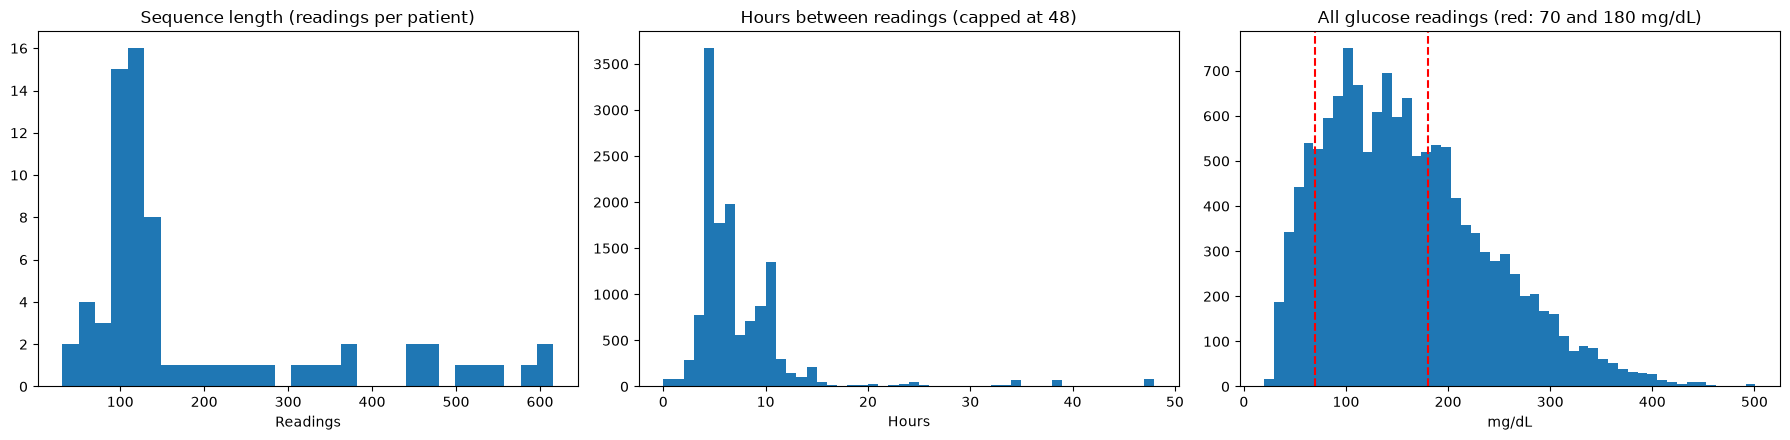

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].hist(per_patient, bins=30, color="tab:blue")
axes[0].set_title("Sequence length (readings per patient)")
axes[0].set_xlabel("Readings")
axes[1].hist(gap_hours.dropna().clip(upper=48), bins=48, color="tab:blue")
axes[1].set_title("Hours between readings (capped at 48)")
axes[1].set_xlabel("Hours")
axes[2].hist(g["glucose"], bins=50, color="tab:blue")
for cut in [70, 180]:
    axes[2].axvline(cut, color="red", linestyle="--")
axes[2].set_title("All glucose readings (red: 70 and 180 mg/dL)")
axes[2].set_xlabel("mg/dL")
plt.tight_layout()
plt.savefig("figures/pbl3/fig01_temporal_structure.png", dpi=150, bbox_inches="tight")
plt.show()

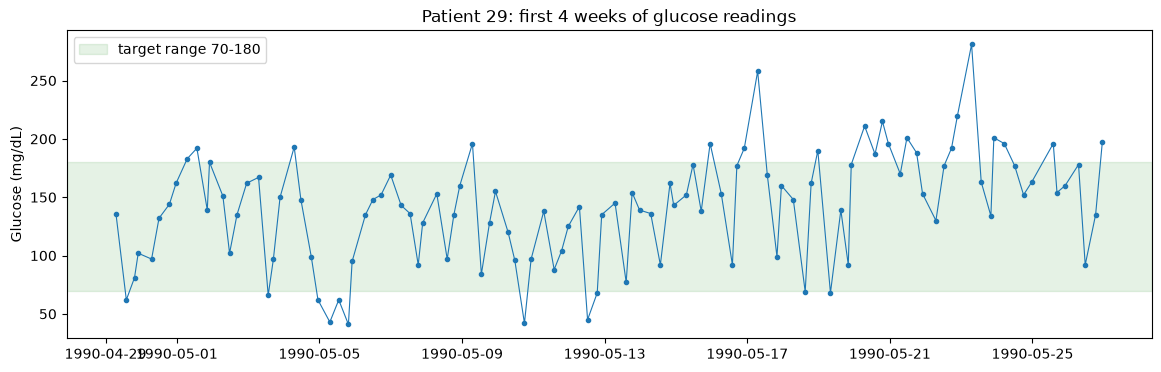

In [6]:
example = g[g["patient"] == per_patient.idxmax()]
first_month = example[example["datetime"] < example["datetime"].min() + pd.Timedelta(days=28)]

plt.figure(figsize=(14, 4))
plt.plot(first_month["datetime"], first_month["glucose"], marker=".", linewidth=0.8)
plt.axhspan(70, 180, color="green", alpha=0.1, label="target range 70-180")
plt.title(f"Patient {per_patient.idxmax()}: first 4 weeks of glucose readings")
plt.ylabel("Glucose (mg/dL)")
plt.legend()
plt.savefig("figures/pbl3/fig02_example_sequence.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** - **Length:** patients have a median of **120 readings** (from 31 to 616), so the sequences are long enough to learn transitions.
- **Gaps:** readings are a median of **6 hours** apart, mostly before meals: pre-breakfast (3,516), pre-supper (3,156), pre-lunch (2,766), plus 2,869 unspecified. After-meal readings are rare (post-breakfast only 20).
- **Order matters:** the lag-1 autocorrelation is **0.186**, and it drops to **0.0** when the order is shuffled. So a reading carries some information about the next one, but each reading is noisy. That suits an HMM: a hidden regime that changes slowly, seen through noisy readings.
- **Example:** the example patient's readings swing in and out of the target band from one reading to the next.

## B.4 Sequential preprocessing
- **Order:** readings are sorted by time inside each patient (done above). An HMM is all about order, so this is essential.
- **Short sequences:** a patient with only a few readings says little about transitions, so we keep patients with **at least 50 readings**.
- **Split by patient, not by reading.** If readings of the same patient were in both train and test, the test would be too easy (leakage). We put 80% of the **patients** in training and 20% in test.
- **Concatenate + lengths.** `hmmlearn` takes all sequences stacked into one column `X`, plus a list `lengths` saying where each patient's sequence ends. This way the model never treats the jump from one patient to the next as a real transition.
- **No scaling.** There is only one feature, and keeping mg/dL makes the state means directly readable.
- **One step = one reading.** The HMM does not know the clock time between readings (see limitations).

In [7]:
long_enough = per_patient[per_patient >= 50].index
g = g[g["patient"].isin(long_enough)]

train_ids, test_ids = train_test_split(long_enough.values, test_size=0.2, random_state=RANDOM_STATE)
train = g[g["patient"].isin(train_ids)]
test = g[g["patient"].isin(test_ids)]

X_train = train["glucose"].values.reshape(-1, 1)       # hmmlearn wants a 2-D column
len_train = train.groupby("patient", sort=False).size().values
X_test = test["glucose"].values.reshape(-1, 1)
len_test = test.groupby("patient", sort=False).size().values

print("Patients kept:", len(long_enough), " train:", len(train_ids), " test:", len(test_ids))
print("Readings  train:", len(X_train), " test:", len(X_test))

Patients kept: 68  train: 54  test: 14
Readings  train: 10504  test: 2931


# Section C: Implementing the HMM *(Rubric 2)*

## C.1 How many hidden states?
We fit HMMs with $K = 2 \dots 6$ states on the **training** patients and compare them with BIC (lower is better):
$$\text{BIC} = -2\log L + p\log N$$
Baum-Welch only finds a local maximum, so each $K$ is fitted from 5 random starts and the best one (highest training log-likelihood) is kept. The small helper below does that, because we need it more than once.

In [8]:
def fit_best_hmm(k, X, lengths, n_starts=5):
    # fit k-state Gaussian HMMs from several random starts, return the one with the highest log-likelihood
    best = None
    for seed in range(n_starts):
        model = GaussianHMM(n_components=k, covariance_type="diag", n_iter=200,
                            tol=1e-4, random_state=RANDOM_STATE + seed)
        model.fit(X, lengths)
        if best is None or model.score(X, lengths) > best.score(X, lengths):
            best = model
    return best

rows = []
for k in range(2, 7):
    m = fit_best_hmm(k, X_train, len_train)
    state_means = np.sort(m.means_.ravel()).round(0)
    rows.append([k, m.bic(X_train, len_train), m.score(X_train, len_train), state_means])
k_table = pd.DataFrame(rows, columns=["K", "BIC", "train_log_lik", "state means (mg/dL)"])
k_table.round(1)

,K,BIC,train_log_lik,state means (mg/dL)
0,2,119499.6,-59717.4,"[117.0, 184.0]"
1,3,118681.0,-59275.7,"[75.0, 126.0, 206.0]"
2,4,118236.3,-59011.7,"[74.0, 113.0, 177.0, 209.0]"
3,5,117957.4,-58821.3,"[74.0, 117.0, 180.0, 191.0, 211.0]"
4,6,118061.4,-58813.1,"[74.0, 84.0, 121.0, 189.0, 192.0, 306.0]"


**Observation:** BIC keeps falling up to **K = 5** (117,957.4) and rises at K = 6, so BIC alone would choose 5 states. But from K = 4 on, the extra states have **overlapping means** (177 and 209 for K = 4; 180, 191 and 211 for K = 5). They split the high range by how much the readings vary, not by glucose level, which is hard to explain to a clinician. **K = 3** gives three clearly separated means (**75, 126 and 206 mg/dL**) that line up with the clinical bands: low, in target (70-180) and high. We choose **K = 3 for interpretability**, and we say openly that BIC would prefer 5.

## C.2 Training the final model with Baum-Welch
`hmmlearn` records the log-likelihood after every Baum-Welch round in `model.monitor_.history`, so we can check that EM climbed and converged.

Converged: True after 136 Baum-Welch rounds


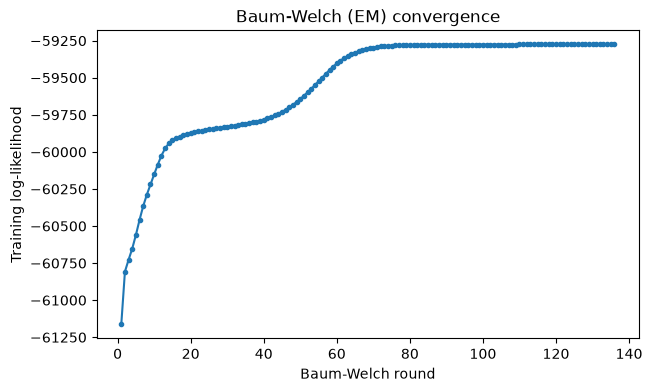

In [9]:
N_STATES = 3     # chosen in C.1
hmm = fit_best_hmm(N_STATES, X_train, len_train)

print("Converged:", hmm.monitor_.converged, "after", hmm.monitor_.iter, "Baum-Welch rounds")
history = list(hmm.monitor_.history)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(history) + 1), history, marker=".")
plt.xlabel("Baum-Welch round")
plt.ylabel("Training log-likelihood")
plt.title("Baum-Welch (EM) convergence")
plt.savefig("figures/pbl3/fig03_baum_welch.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** Baum-Welch converged after **136 rounds**, and the training log-likelihood never went down, as EM guarantees. The curve has a flat stretch between about rounds 15 and 40, then a second climb. This is typical of EM: it can stay near a poor solution for a while before finding a better one, which is why we also use 5 random starts.

## C.3 The learned parameters
State numbers from EM are arbitrary, so we **sort the states by mean glucose** and give them names. `order[r]` is the original state with rank `r`; `rank[s]` is the rank of original state `s`.

**Expected time in a state.** If the chance of staying is $a_{ii}$, the number of readings spent in state $i$ before leaving follows a geometric distribution with mean
$$E[\text{duration}_i] = \frac{1}{1 - a_{ii}}$$

In [10]:
order = np.argsort(hmm.means_.ravel())          # states sorted from lowest to highest glucose
rank = np.empty(N_STATES, dtype=int)
rank[order] = np.arange(N_STATES)
names = ["Low", "Target", "High"]

A = hmm.transmat_[order][:, order]               # transition matrix in sorted order
params = pd.DataFrame({
    "mean (mg/dL)": hmm.means_.ravel()[order],
    "std (mg/dL)": np.sqrt(hmm.covars_.ravel()[order]),
    "start prob": hmm.startprob_[order],
    "stay prob a_ii": np.diag(A),
    "expected readings in state": 1 / (1 - np.diag(A)),
}, index=names)
params.round(3)

,mean (mg/dL),std (mg/dL),start prob,stay prob a_ii,expected readings in state
Low,74.782,24.095,0.113,0.429,1.750
Target,126.146,37.820,0.137,0.970,33.720
High,205.539,76.561,0.750,0.788,4.718


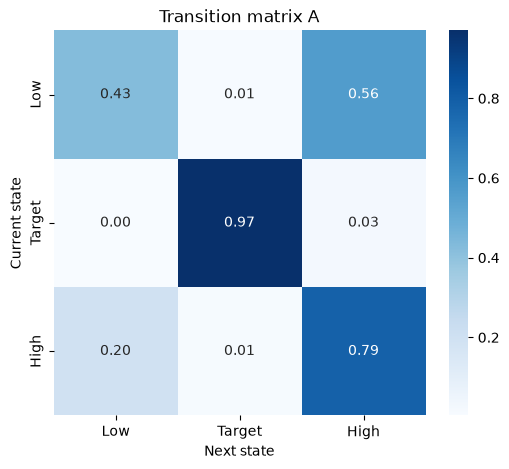

In [11]:
plt.figure(figsize=(6, 5))
sns.heatmap(pd.DataFrame(A, index=names, columns=names), annot=True, fmt=".2f", cmap="Blues")
plt.xlabel("Next state")
plt.ylabel("Current state")
plt.title("Transition matrix A")
plt.savefig("figures/pbl3/fig04_transition_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** - **Low** (mean 74.8, SD 24.1 mg/dL): staying probability only **0.43**, so it lasts about **1.75 readings**. These are short dips, which patients correct quickly by eating.
- **Target** (mean 126.1, SD 37.8): staying probability **0.97**, so it lasts about **33.7 readings**. Low and High almost never jump into it (0.01). It behaves like a separate **stable, well-controlled regime** that some patients stay in for long periods.
- **High** (mean 205.5, with a wide SD of 76.6): lasts about **4.7 readings**, and from High there is a 0.20 chance of dropping to Low.
- **Rebound:** from Low, the most likely next state is High (**0.56**). This matches the known rebound after a hypoglycaemic episode (over-correcting with food, plus the body's counter-regulatory hormones).
- **Start:** most sequences start in High (start probability 0.75).

## C.3b Long-run behaviour: k-step transitions and the stationary distribution
Two Markov-chain results from Unit 4:
- **k-step transitions.** The probability of being in state $j$ after $k$ steps, starting from $i$, is the $(i, j)$ entry of the matrix power $A^k$:
$$P(z_{t+k} = j \mid z_t = i) = (A^k)_{ij}$$
- **Stationary distribution.** A distribution $\pi^*$ that one more transition does not change. It is the long-run share of time spent in each state:
$$\pi^* = \pi^* A \qquad \sum_i \pi^*_i = 1$$
$\pi^*$ is the left eigenvector of $A$ with eigenvalue 1, normalised to sum to 1.

We compare $\pi^*$ with the share of training readings that Viterbi actually assigns to each state.

In [12]:
# k-step transitions starting from Low (row 0 of A^k)
k_steps = pd.DataFrame([np.linalg.matrix_power(A, k)[0] for k in [1, 2, 5, 20, 100]],
                       index=["k = 1", "k = 2", "k = 5", "k = 20", "k = 100"], columns=names)
print("Starting from Low, probability of each state after k readings:")
print(k_steps.round(3))

# stationary distribution: left eigenvector of A for eigenvalue 1
eigvals, eigvecs = np.linalg.eig(A.T)
stationary = np.real(eigvecs[:, np.argmin(np.abs(eigvals - 1))])
stationary = stationary / stationary.sum()

decoded_train = rank[hmm.predict(X_train, len_train)]          # Viterbi states of all training readings
observed_share = np.bincount(decoded_train, minlength=N_STATES) / len(decoded_train)
pd.DataFrame({"stationary pi*": stationary, "share of training readings (Viterbi)": observed_share},
             index=names).round(3)

Starting from Low, probability of each state after k readings:
           Low  Target   High
k = 1    0.429   0.008  0.563
k = 2    0.296   0.019  0.685
k = 5    0.250   0.050  0.701
k = 20   0.220   0.157  0.622
k = 100  0.189   0.276  0.536


,stationary pi*,share of training readings (Viterbi)
Low,0.188,0.208
Target,0.280,0.304
High,0.532,0.487


**Observation:** - **k-step transitions:** from Low, the chain usually moves to High at once (**0.563** after one reading). The starting state is forgotten only slowly: after 100 readings the probabilities (0.189 / 0.276 / 0.536) are almost the stationary ones. Convergence is slow because Target is so sticky (a_ii = 0.97).
- **Stationary distribution:** **π\* = (0.188 Low, 0.280 Target, 0.532 High)**, so in the long run about half of all readings are expected to be High.
- **Check:** this is close to the share of training readings that Viterbi actually assigns to each state (0.208 / 0.304 / 0.487), so the learned transition matrix reproduces the long-run occupancy of the data.

## C.4 Checking the library against the formulas
To show that we understand what `hmmlearn` computes, we write the **forward** and **Viterbi** recursions from A.3 ourselves (in log space) and compare them with the library on one test patient.
- Forward: $\log\alpha_t(j) = \log b_j(x_t) + \log\sum_i \exp\big(\log\alpha_{t-1}(i) + \log a_{ij}\big)$. It should give the same $\log P(x_{1:T})$ as `hmm.score`.
- Viterbi: the same with $\max$ instead of $\log\sum\exp$, plus back-pointers. It should give the same path as `hmm.decode`.

The forward function also returns the **filtered** probabilities $P(z_t \mid x_{1:t})$ (normalised $\alpha_t$), which we reuse for forecasting in D.3.

In [13]:
def forward(x, model):
    # forward algorithm in log space: returns P(z_t | x_1..t) for every t, and log P(x_1..T)
    log_b = norm.logpdf(x[:, None], model.means_.ravel(), np.sqrt(model.covars_.ravel()))  # (T, K)
    log_A = np.log(model.transmat_)
    log_alpha = np.log(model.startprob_) + log_b[0]
    filtered = [np.exp(log_alpha - logsumexp(log_alpha))]
    for t in range(1, len(x)):
        log_alpha = logsumexp(log_alpha[:, None] + log_A, axis=0) + log_b[t]
        filtered.append(np.exp(log_alpha - logsumexp(log_alpha)))
    return np.array(filtered), logsumexp(log_alpha)

In [14]:
def viterbi(x, model):
    # Viterbi algorithm in log space: returns the most likely state path and its log-probability
    log_b = norm.logpdf(x[:, None], model.means_.ravel(), np.sqrt(model.covars_.ravel()))
    log_A = np.log(model.transmat_)
    delta = np.log(model.startprob_) + log_b[0]
    back = np.zeros((len(x), model.n_components), dtype=int)
    for t in range(1, len(x)):
        scores = delta[:, None] + log_A          # scores[i, j]: best path ending in i, then i -> j
        back[t] = scores.argmax(axis=0)          # best previous state for each j
        delta = scores.max(axis=0) + log_b[t]
    path = [delta.argmax()]
    for t in range(len(x) - 1, 0, -1):           # follow the back-pointers from the end
        path.append(back[t, path[-1]])
    return np.array(path[::-1]), delta.max()

In [15]:
x_one = test[test["patient"] == test_ids[0]]["glucose"].values

_, our_log_lik = forward(x_one, hmm)
our_path, our_best = viterbi(x_one, hmm)
lib_best, lib_path = hmm.decode(x_one.reshape(-1, 1), algorithm="viterbi")

print("Forward  log P(x): ours", round(our_log_lik, 4), " hmmlearn", round(hmm.score(x_one.reshape(-1, 1)), 4))
print("Viterbi  log P(best path): ours", round(our_best, 4), " hmmlearn", round(lib_best, 4))
print("Viterbi paths identical:", bool(np.all(our_path == lib_path)), f"({len(x_one)} readings)")

Forward  log P(x): ours -600.2392  hmmlearn -600.2392
Viterbi  log P(best path): ours -613.0105  hmmlearn -613.0105
Viterbi paths identical: True (104 readings)


**Observation:** Our hand-written forward algorithm gives **exactly the same log-likelihood** as `hmmlearn` (-600.2392). Our Viterbi gives the same best-path log-probability (-613.0105) and an **identical state path** for all 104 readings. So the library is doing exactly what the formulas in A.3 say. The best single path (-613.0) is less likely than the whole sequence (-600.2), because forward **sums over all** possible paths while Viterbi keeps only the **best one**.

# Section D: Evaluation and Interpretation *(Rubric 3)*

## D.1 Does the time order help? (test log-likelihood)
The fairest test of an HMM is whether it explains **new patients' sequences** better than models that ignore time. We compare the average log-likelihood per reading on the test patients:
- **HMM** (3 states, uses order through $A$)
- **GMM** with the same 3 Gaussians but no transitions (every reading treated as independent; this is the PBL 2 model)
- **One Gaussian** for all readings

Higher (less negative) is better.

In [16]:
gmm3 = GaussianMixture(n_components=N_STATES, n_init=5, random_state=RANDOM_STATE).fit(X_train)
gmm1 = GaussianMixture(n_components=1, random_state=RANDOM_STATE).fit(X_train)

ll_table = pd.DataFrame({
    "test log-lik per reading": [hmm.score(X_test, len_test) / len(X_test),
                                 gmm3.score(X_test), gmm1.score(X_test)],
}, index=["HMM (3 states)", "GMM (3 groups, no time)", "Single Gaussian"])
ll_table.round(4)

,test log-lik per reading
HMM (3 states),-5.6847
"GMM (3 groups, no time)",-5.7313
Single Gaussian,-5.7861


**Observation:** On the 14 unseen test patients, the **HMM explains the sequences best (-5.6847 per reading)**, ahead of the GMM with the same three Gaussians (-5.7313) and a single Gaussian (-5.7861). The only difference between the HMM and the GMM is the transition matrix. Using the time order gains about as much as going from one Gaussian to three. So the sequential structure is real, and it generalises to new patients.

## D.2 Decoding a test patient: Viterbi path and forward-backward probabilities
Top: the patient's readings, coloured by the **Viterbi** state (the single most likely regime sequence).
Bottom: the **forward-backward** posterior $\gamma_t(i) = P(z_t = i \mid x_{1:T})$, which shows how sure the model is at every reading (`hmm.predict_proba`).

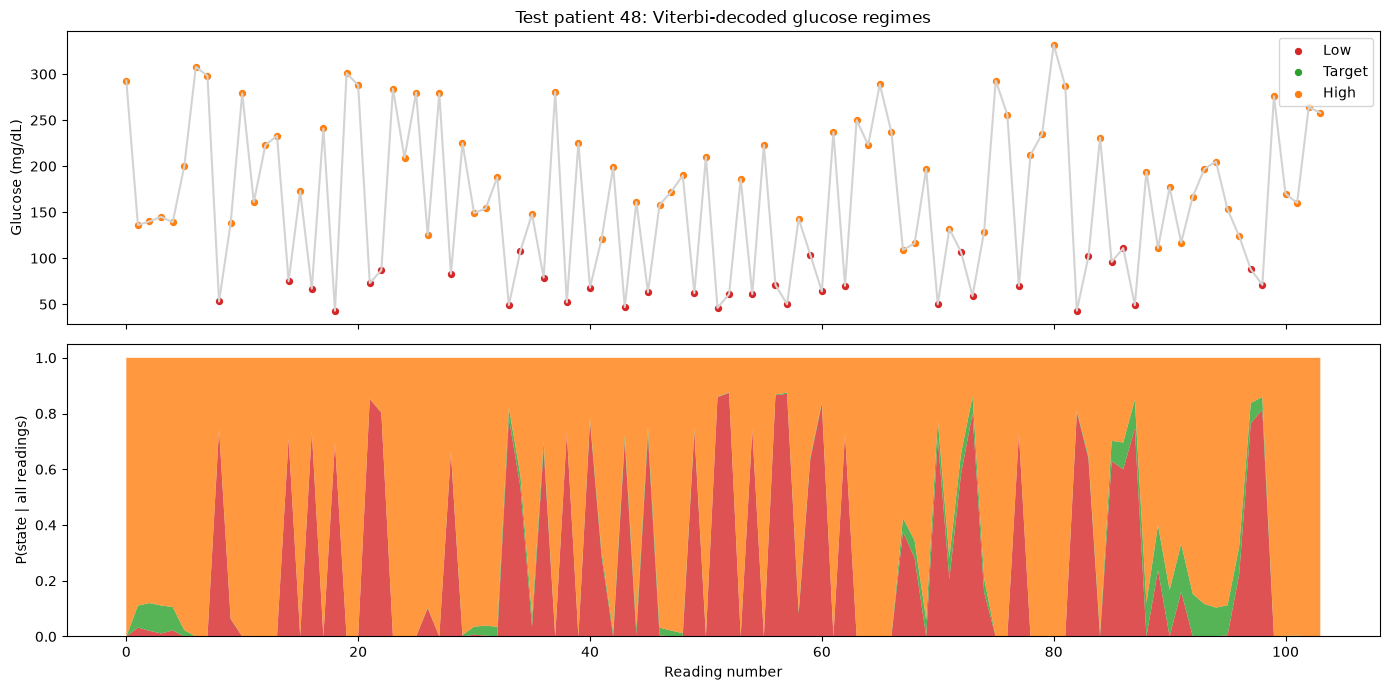

In [17]:
pid = test_ids[0]
seq = test[test["patient"] == pid].head(120)              # first 120 readings, for readability
x_seq = seq["glucose"].values.reshape(-1, 1)
path = rank[hmm.predict(x_seq)]                            # Viterbi path, in sorted state numbers
post = hmm.predict_proba(x_seq)[:, order]                 # forward-backward posteriors, sorted

colours = ["tab:red", "tab:green", "tab:orange"]
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(range(len(seq)), seq["glucose"], color="lightgrey")
for s in range(N_STATES):
    axes[0].scatter(np.where(path == s)[0], seq["glucose"].values[path == s], color=colours[s], s=18, label=names[s])
axes[0].set_ylabel("Glucose (mg/dL)")
axes[0].set_title(f"Test patient {pid}: Viterbi-decoded glucose regimes")
axes[0].legend()
axes[1].stackplot(range(len(seq)), post.T, colors=colours, labels=names, alpha=0.8)
axes[1].set_ylabel("P(state | all readings)")
axes[1].set_xlabel("Reading number")
plt.tight_layout()
plt.savefig("figures/pbl3/fig05_viterbi_posterior.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** This test patient (patient 48) swings between about 40 and 330 mg/dL. Viterbi puts the patient mostly in **High, with frequent short drops to Low**, and **never in Target**. The forward-backward plot shows the model is sure about High most of the time, gives Low up to about 0.85 probability at the dips, and is less certain only near the end of the window. The HMM summarises this patient as **unstable control: high glucose with repeated hypoglycaemic dips**, a pattern that one average value would hide.

## D.3 Forecasting the next reading
An HMM can also **predict**. After reading $t$, the forward algorithm gives $P(z_t \mid x_{1:t})$. One step of the chain gives the next state, and the expected next reading is
$$\hat{x}_{t+1} = \sum_{j} P(z_{t+1} = j \mid x_{1:t})\,\mu_j \qquad \text{with} \qquad P(z_{t+1} = j \mid x_{1:t}) = \sum_i P(z_t = i \mid x_{1:t})\, a_{ij}$$
We compare its mean absolute error (MAE) on the test patients with two simple baselines:
- **Training mean:** always predict the average glucose of the training patients.
- **Last reading:** predict that the next reading equals the current one.

In [18]:
errors = {"HMM forecast": [], "Training mean": [], "Last reading": []}
train_mean = X_train.mean()

for pid in test_ids:
    x = test[test["patient"] == pid]["glucose"].values
    filtered, _ = forward(x, hmm)
    next_state = filtered[:-1] @ hmm.transmat_           # P(z_t+1 | x_1..t) for t = 1..T-1
    forecast = next_state @ hmm.means_.ravel()
    actual = x[1:]
    errors["HMM forecast"].extend(np.abs(forecast - actual))
    errors["Training mean"].extend(np.abs(train_mean - actual))
    errors["Last reading"].extend(np.abs(x[:-1] - actual))

pd.Series({name: np.mean(e) for name, e in errors.items()}, name="MAE (mg/dL)").round(1)

HMM forecast     60.1
Training mean    62.6
Last reading     74.0
Name: MAE (mg/dL), dtype: float64

**Observation:** The HMM forecast has the lowest error: **MAE 60.1 mg/dL**, against 62.6 for the training mean and **74.0 for copying the last reading**. The gain over the mean is small. Readings are about 6 hours apart and only weakly related (lag-1 r = 0.186), so the exact next value is hard to predict. Copying the last reading is the worst, because it copies that reading's noise. The HMM instead uses the **regime**, which changes more slowly than a single reading.

## D.4 When in the day is each regime most common?
We decode every test patient with Viterbi and count which state is active in each meal slot. The model never saw the slot, so any pattern here is a discovery, not something we put in.

In [19]:
test = test.copy()
test["state"] = ""
for pid in test_ids:
    mask = test["patient"] == pid
    states = rank[hmm.predict(test.loc[mask, "glucose"].values.reshape(-1, 1))]
    test.loc[mask, "state"] = [names[s] for s in states]

slot_order = ["pre-breakfast", "post-breakfast", "pre-lunch", "post-lunch", "pre-supper",
              "post-supper", "pre-snack", "unspecified"]
by_slot = pd.crosstab(test["slot"], test["state"], normalize="index").reindex(slot_order)[names] * 100
by_slot["readings"] = test["slot"].value_counts()
by_slot.round(1)

state,Low,Target,High,readings
slot,,,,
pre-breakfast,14.8,22.2,63.0,789
post-breakfast,33.3,33.3,33.3,3
pre-lunch,22.5,28.1,49.4,605
post-lunch,11.8,11.8,76.5,17
pre-supper,17.0,25.0,58.1,713
post-supper,24.6,4.9,70.5,61
pre-snack,29.9,18.2,51.9,187
unspecified,15.8,28.4,55.8,556


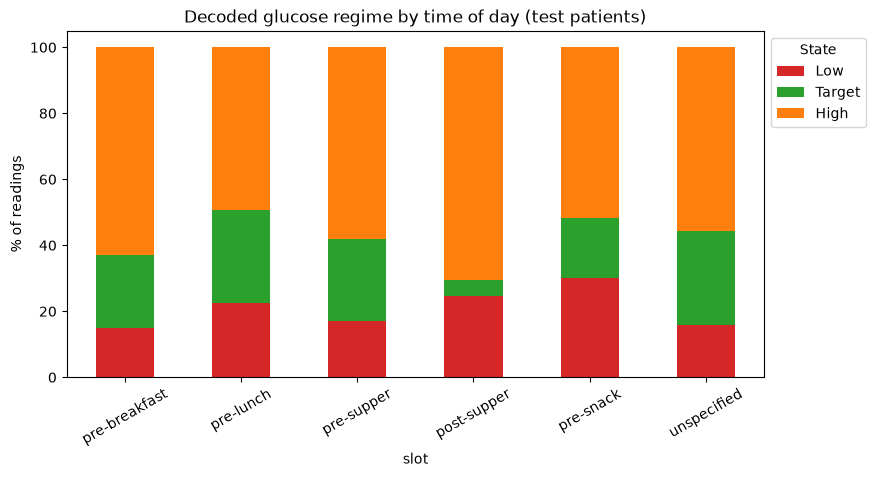

In [20]:
plot_slots = by_slot[by_slot["readings"] >= 30][names]       # skip slots with very few readings
plot_slots.plot(kind="bar", stacked=True, color=colours, figsize=(9, 4.5))
plt.ylabel("% of readings")
plt.title("Decoded glucose regime by time of day (test patients)")
plt.xticks(rotation=30)
plt.legend(title="State", bbox_to_anchor=(1, 1))
plt.savefig("figures/pbl3/fig06_state_by_slot.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** In every meal slot with enough readings, **High** is the most common regime. It is most common **before breakfast (63.0%)**, more than before lunch (49.4%) or supper (58.1%). This fits the known early-morning rise in glucose (the "dawn phenomenon", and evening insulin wearing off overnight). **Low** is most common **pre-snack (29.9%)** and **post-supper (24.6%)**, i.e. in the evening, a known time for insulin-related lows. Post-breakfast (3 readings) and post-lunch (17) are too small to trust and are left out of the plot.

## D.5 Patient risk profiles
The share of time each test patient spends in each regime is an easy-to-explain summary of their glucose control (similar to the clinical measure "time in range").

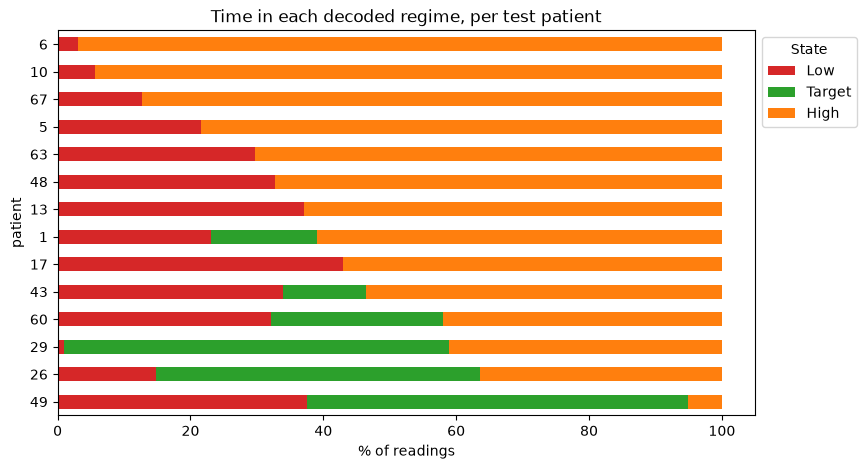

state,Low,Target,High
patient,,,
49,37.6,57.4,5.1
26,14.8,48.9,36.4
29,1.0,58.0,41.1
60,32.1,25.9,42.0
43,33.9,12.5,53.6
17,43.0,0.0,57.0
1,23.0,16.0,61.0
13,37.1,0.0,62.9
48,32.7,0.0,67.3


In [21]:
profile = pd.crosstab(test["patient"], test["state"], normalize="index")[names] * 100
profile = profile.sort_values("High")
profile.plot(kind="barh", stacked=True, color=colours, figsize=(9, 5))
plt.xlabel("% of readings")
plt.title("Time in each decoded regime, per test patient")
plt.legend(title="State", bbox_to_anchor=(1, 1))
plt.savefig("figures/pbl3/fig07_patient_profiles.png", dpi=150, bbox_inches="tight")
plt.show()
profile.round(1)

**Observation:** The test patients split into two kinds:
- **Four patients (49, 26, 29, 60)** spend 26% to 58% of their readings in Target. Patient 49 is the best controlled, with only 5.1% High.
- **The other ten** spend 16% or less in Target, and **eight of them never** enter it. Patient 6 is the worst, with 96.9% High.

The decoded regimes therefore give a simple, explainable **risk ranking** of patients by glucose control, without any labels.

# Section E: Conclusion

- **New sequential data:** the AIM-94 dataset has 13,515 glucose readings from 70 insulin-dependent patients. We sorted the readings by time, kept the 68 patients with at least 50 readings, and split by patient.
- **Model:** a 3-state Gaussian HMM (Low, Target, High) trained with **Baum-Welch (EM)**. Our hand-written **forward** and **Viterbi** algorithms matched `hmmlearn` exactly.
- **Evaluation:** on new patients, the HMM beats the same mixture without time (log-likelihood -5.685 vs -5.731) and gives the best next-reading forecast (MAE 60.1 vs 62.6 and 74.0).
- **Interpretation:**
  - Lows are short and are usually followed by highs (rebound).
  - A stable Target regime exists, but only some patients reach it.
  - Highs peak before breakfast and lows in the evening.
  - The share of time in each regime ranks patients by glucose control.
- **Link to PBL 2:** Baum-Welch is the same alternating EM as in PBL 2. The HMM adds one thing, the transition matrix, and that is exactly what makes it better on sequences.

**Limitations**
- **Irregular time steps.** One HMM step is one reading, whether the gap was 3 hours or 2 days. A continuous-time model would handle this properly.
- **Paper records** have fixed times (08:00, 12:00, ...), so the clock times are only approximate.
- **Glucose only.** Insulin doses, meals and exercise are in the data but not used; an input-output HMM could add them.
- **Small and old data:** 70 patients with Type 1 diabetes from the early 1990s, with home meters of that time.
- Associations, not diagnoses. This is a decision-support prototype.